In [95]:
import matplotlib.pyplot as plt
import pandas as pd 
import numpy as np 

In [96]:
df = pd.read_csv("telecom_churn.csv")
df.isnull().sum()


customer_id            0
signup_date            0
age                  122
gender                 0
city                   0
contract_type          0
internet_service       0
tenure_months          0
monthly_charges        0
total_charges         91
support_calls         60
churn                  0
churn_reason        1986
dtype: int64

In [97]:
df.head()

,customer_id,signup_date,age,gender,city,contract_type,internet_service,tenure_months,monthly_charges,total_charges,support_calls,churn,churn_reason
0,CUST2875,2025-07-28,59.0,Female,Mumbai,Two year,Fiber,45.0,92.16,NaN,3.0,No,NaN
1,CUST1617,2025-12-03,19.0,FEMALE,Hyderabad,Two year,Fiber,25.0,81.70,1953.36,3.0,No,NaN
2,CUST2691,2025-09-20,70.0,Female,Pune,One year,Fiber,20.0,92.55,1930.17,0.0,No,NaN
3,CUST3323,2024-04-25,79.0,Male,Pune,Two year,Fiber,62.0,89.55,5352.35,0.0,No,NaN
4,CUST1535,2024-09-25,28.0,Female,Jaipur,Month-to-month,Fiber,19.0,77.85,1427.89,1.0,Yes,Customer Service


In [98]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [99]:
df["gender"].value_counts()

gender
FEMALE     525
Male       521
 Female    515
male       471
Female     468
Name: count, dtype: int64

In [100]:
df["gender"] = df["gender"].str.lower()
df["gender"] = df["gender"].str.strip()
df["gender"].value_counts()

gender
female    1508
male       992
Name: count, dtype: int64

In [101]:
df.loc[df["monthly_charges"] <= 0 , "monthly_charges"] = np.nan
df.isnull().sum()

customer_id            0
signup_date            0
age                  120
gender                 0
city                   0
contract_type          0
internet_service       0
tenure_months          0
monthly_charges       25
total_charges         90
support_calls         60
churn                  0
churn_reason        1955
dtype: int64

In [102]:
df

,customer_id,signup_date,age,gender,city,contract_type,internet_service,tenure_months,monthly_charges,total_charges,support_calls,churn,churn_reason
0,CUST2875,2025-07-28,59.0,female,Mumbai,Two year,Fiber,45.0,92.16,NaN,3.0,No,NaN
1,CUST1617,2025-12-03,19.0,female,Hyderabad,Two year,Fiber,25.0,81.70,1953.36,3.0,No,NaN
2,CUST2691,2025-09-20,70.0,female,Pune,One year,Fiber,20.0,92.55,1930.17,0.0,No,NaN
3,CUST3323,2024-04-25,79.0,male,Pune,Two year,Fiber,62.0,89.55,5352.35,0.0,No,NaN
4,CUST1535,2024-09-25,28.0,female,Jaipur,Month-to-month,Fiber,19.0,77.85,1427.89,1.0,Yes,Customer Service
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2535,CUST3304,2025-01-10,27.0,male,Mumbai,Month-to-month,DSL,10.0,69.36,670.09,4.0,No,NaN
2536,CUST1968,2024-10-07,22.0,female,Delhi,Two year,Fiber,15.0,90.41,1407.93,NaN,No,NaN
2537,CUST2667,2024-04-21,76.0,female,Pune,Month-to-month,DSL,15.0,49.57,747.19,4.0,No,NaN
2538,CUST2688,2024-01-23,55.0,female,Mumbai,One year,Fiber,10.0,88.24,881.75,1.0,No,NaN


In [103]:
df.groupby("internet_service")["monthly_charges"].transform("median")

0       84.93
1       84.93
2       84.93
3       84.93
4       84.93
        ...  
2535    55.46
2536    84.93
2537    55.46
2538    84.93
2539    55.46
Name: monthly_charges, Length: 2500, dtype: float64

In [104]:
df["internet_service"].value_counts()
df["monthly_charges"] = df["monthly_charges"].fillna(df.groupby("internet_service")["monthly_charges"].transform("median"))

In [105]:
df["age"] = df["age"].fillna(df["age"].median())

In [106]:
df.isnull().sum()

customer_id            0
signup_date            0
age                    0
gender                 0
city                   0
contract_type          0
internet_service       0
tenure_months          0
monthly_charges        0
total_charges         90
support_calls         60
churn                  0
churn_reason        1955
dtype: int64

In [107]:
df["support_calls"] = df["support_calls"].fillna(df.groupby("contract_type")["support_calls"].transform("median"))
df["total_charges"] = df["total_charges"].fillna(df["tenure_months"]	* df["monthly_charges"])

In [108]:
df.isnull().sum()
df.dtypes

customer_id          object
signup_date          object
age                 float64
gender               object
city                 object
contract_type        object
internet_service     object
tenure_months       float64
monthly_charges     float64
total_charges       float64
support_calls       float64
churn                object
churn_reason         object
dtype: object

In [109]:
df["signup_date"] = pd.to_datetime(df["signup_date"])

In [110]:
df.isnull().sum()
df.dtypes

customer_id                 object
signup_date         datetime64[ns]
age                        float64
gender                      object
city                        object
contract_type               object
internet_service            object
tenure_months              float64
monthly_charges            float64
total_charges              float64
support_calls              float64
churn                       object
churn_reason                object
dtype: object

In [111]:
df["signup_month"] = df["signup_date"].dt.to_period("M")

In [112]:
condition = [ (df["age"] >= 18)  & (df["age"] <= 25) ,
             (df["age"] >= 26)  & (df["age"] <= 35),
             (df["age"] >= 36)  & (df["age"] <= 50),
             (df["age"] >= 51)  & (df["age"] <= 65),
             (df["age"] > 65)]                                           # 18-25, 26-35, 36-50, 51-65, 65+.
choices = ["18-25", "26-35" , "36-50" , "51-65" , "65 +" ]
df["age group"] = np.select(condition , choices , default="Unknown")


In [113]:
df.head()

,customer_id,signup_date,age,gender,city,contract_type,internet_service,tenure_months,monthly_charges,total_charges,support_calls,churn,churn_reason,signup_month,age group
0,CUST2875,2025-07-28,59.0,female,Mumbai,Two year,Fiber,45.0,92.16,4147.20,3.0,No,NaN,2025-07,51-65
1,CUST1617,2025-12-03,19.0,female,Hyderabad,Two year,Fiber,25.0,81.70,1953.36,3.0,No,NaN,2025-12,18-25
2,CUST2691,2025-09-20,70.0,female,Pune,One year,Fiber,20.0,92.55,1930.17,0.0,No,NaN,2025-09,65 +
3,CUST3323,2024-04-25,79.0,male,Pune,Two year,Fiber,62.0,89.55,5352.35,0.0,No,NaN,2024-04,65 +
4,CUST1535,2024-09-25,28.0,female,Jaipur,Month-to-month,Fiber,19.0,77.85,1427.89,1.0,Yes,Customer Service,2024-09,26-35


In [114]:
df["churn_flag"]  = np.select([df["churn"] == "Yes"] , [1] , default= 0 )

In [115]:
df.head()

,customer_id,signup_date,age,gender,city,contract_type,internet_service,tenure_months,monthly_charges,total_charges,support_calls,churn,churn_reason,signup_month,age group,churn_flag
0,CUST2875,2025-07-28,59.0,female,Mumbai,Two year,Fiber,45.0,92.16,4147.20,3.0,No,NaN,2025-07,51-65,0
1,CUST1617,2025-12-03,19.0,female,Hyderabad,Two year,Fiber,25.0,81.70,1953.36,3.0,No,NaN,2025-12,18-25,0
2,CUST2691,2025-09-20,70.0,female,Pune,One year,Fiber,20.0,92.55,1930.17,0.0,No,NaN,2025-09,65 +,0
3,CUST3323,2024-04-25,79.0,male,Pune,Two year,Fiber,62.0,89.55,5352.35,0.0,No,NaN,2024-04,65 +,0
4,CUST1535,2024-09-25,28.0,female,Jaipur,Month-to-month,Fiber,19.0,77.85,1427.89,1.0,Yes,Customer Service,2024-09,26-35,1


In [116]:
total_charm = (df["churn_flag"] == 1).sum()
total_customer = df["customer_id"].count()
total_churn_rate = (total_charm / total_customer) * 100 
print("Total churn rate is  : %" , total_churn_rate)


Total churn rate is  : % 21.8


In [117]:
df.groupby("internet_service").agg(rate_no_of_churn = ("churn_flag" , "mean"))

,rate_no_of_churn
internet_service,
DSL,0.198864
Fiber,0.237968
No Internet,0.206827


So , hear the fiber have the highst churn rate 

In [118]:
df.groupby("contract_type").agg(rate_no_of_churn = ("churn_flag" , "mean"))

,rate_no_of_churn
contract_type,
Month-to-month,0.331224
One year,0.085179
Two year,0.048880


So hear the month-to-month have the most churn rate

In [119]:
df4 = df.groupby(["internet_service" , "contract_type"]).agg(churen_rate = ("churn_flag" , "mean"))
df4.sort_values( "churen_rate" , ascending=False)

churen_rate
internet_service contract_type              
Fiber            Month-to-month     0.349920
No Internet      Month-to-month     0.318182
DSL              Month-to-month     0.315789
Fiber            One year           0.117216
                 Two year           0.075221
No Internet      One year           0.063063
DSL              One year           0.054187
No Internet      Two year           0.049505
DSL              Two year           0.012195

Fiber and month to month have the max value 

In [120]:
df.head()

,customer_id,signup_date,age,gender,city,contract_type,internet_service,tenure_months,monthly_charges,total_charges,support_calls,churn,churn_reason,signup_month,age group,churn_flag
0,CUST2875,2025-07-28,59.0,female,Mumbai,Two year,Fiber,45.0,92.16,4147.20,3.0,No,NaN,2025-07,51-65,0
1,CUST1617,2025-12-03,19.0,female,Hyderabad,Two year,Fiber,25.0,81.70,1953.36,3.0,No,NaN,2025-12,18-25,0
2,CUST2691,2025-09-20,70.0,female,Pune,One year,Fiber,20.0,92.55,1930.17,0.0,No,NaN,2025-09,65 +,0
3,CUST3323,2024-04-25,79.0,male,Pune,Two year,Fiber,62.0,89.55,5352.35,0.0,No,NaN,2024-04,65 +,0
4,CUST1535,2024-09-25,28.0,female,Jaipur,Month-to-month,Fiber,19.0,77.85,1427.89,1.0,Yes,Customer Service,2024-09,26-35,1


In [121]:
df3 = df.groupby("churn").agg(Avg_monthly_charges = ("monthly_charges" , "mean")).copy()
df3.reset_index(inplace = True)
df3["churn"] = df3["churn"].replace({"No" : "retained" , "Yes" : "churn"})
df3

,churn,Avg_monthly_charges
0,retained,62.170703
1,churn,63.888229


As you can see that the churn coustamer has to pay more as compaired to retained coustomer . 

In [122]:
df.head()

,customer_id,signup_date,age,gender,city,contract_type,internet_service,tenure_months,monthly_charges,total_charges,support_calls,churn,churn_reason,signup_month,age group,churn_flag
0,CUST2875,2025-07-28,59.0,female,Mumbai,Two year,Fiber,45.0,92.16,4147.20,3.0,No,NaN,2025-07,51-65,0
1,CUST1617,2025-12-03,19.0,female,Hyderabad,Two year,Fiber,25.0,81.70,1953.36,3.0,No,NaN,2025-12,18-25,0
2,CUST2691,2025-09-20,70.0,female,Pune,One year,Fiber,20.0,92.55,1930.17,0.0,No,NaN,2025-09,65 +,0
3,CUST3323,2024-04-25,79.0,male,Pune,Two year,Fiber,62.0,89.55,5352.35,0.0,No,NaN,2024-04,65 +,0
4,CUST1535,2024-09-25,28.0,female,Jaipur,Month-to-month,Fiber,19.0,77.85,1427.89,1.0,Yes,Customer Service,2024-09,26-35,1


In [123]:
df4  = df.groupby("age group").agg(Avg_churn_coustomer = ("churn_flag" , "sum"))
df4.sort_values("Avg_churn_coustomer" , inplace = True , ascending = False)
df4

,Avg_churn_coustomer
age group,
36-50,166
51-65,110
65 +,109
26-35,86
18-25,74


Hear the highst value of churn coustomer are of age group 262 to 35 

In [124]:
df.head()

,customer_id,signup_date,age,gender,city,contract_type,internet_service,tenure_months,monthly_charges,total_charges,support_calls,churn,churn_reason,signup_month,age group,churn_flag
0,CUST2875,2025-07-28,59.0,female,Mumbai,Two year,Fiber,45.0,92.16,4147.20,3.0,No,NaN,2025-07,51-65,0
1,CUST1617,2025-12-03,19.0,female,Hyderabad,Two year,Fiber,25.0,81.70,1953.36,3.0,No,NaN,2025-12,18-25,0
2,CUST2691,2025-09-20,70.0,female,Pune,One year,Fiber,20.0,92.55,1930.17,0.0,No,NaN,2025-09,65 +,0
3,CUST3323,2024-04-25,79.0,male,Pune,Two year,Fiber,62.0,89.55,5352.35,0.0,No,NaN,2024-04,65 +,0
4,CUST1535,2024-09-25,28.0,female,Jaipur,Month-to-month,Fiber,19.0,77.85,1427.89,1.0,Yes,Customer Service,2024-09,26-35,1


In [125]:
df5 = df.groupby(["signup_month" , "contract_type"]).agg(Total_counsomer = ("customer_id" , "count"))
df5.reset_index(inplace = True)
df5.head()

,signup_month,contract_type,Total_counsomer
0,2024-01,Month-to-month,57
1,2024-01,One year,23
2,2024-01,Two year,16
3,2024-02,Month-to-month,58
4,2024-02,One year,24


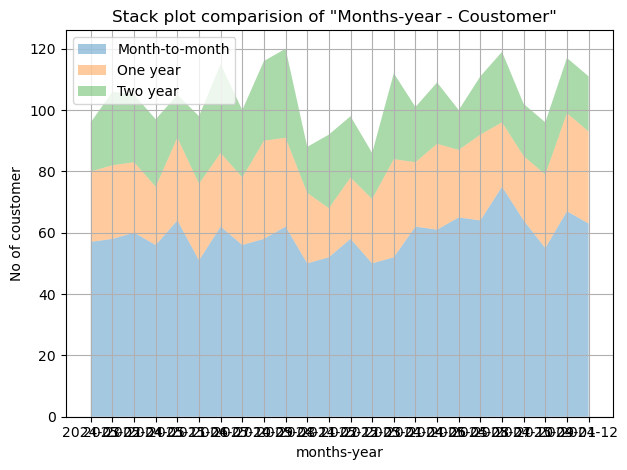

In [138]:
months = df5["signup_month"]
months = list(set(months))
months = [str(item) for item in months]
Month_to_month	=df5[df5["contract_type"] == "Month-to-month"]["Total_counsomer"].tolist()
One_year =df5[df5["contract_type"] == "One year"]["Total_counsomer"].tolist()
Two_year =df5[df5["contract_type"] == "Two year"]["Total_counsomer"].tolist()
labels_ = ["Month-to-month" , "One year" , "Two year"]

plt.stackplot(months , Month_to_month , One_year , Two_year , labels=labels_ , alpha = 0.4)
plt.xlabel("months-year")
plt.ylabel("No of coustomer")
plt.title("Stack plot comparision of \"Months-year - Coustomer\"  ")
plt.grid(True)
plt.tight_layout()
plt.legend(loc = "upper left")

In [139]:
df.head()

,customer_id,signup_date,age,gender,city,contract_type,internet_service,tenure_months,monthly_charges,total_charges,support_calls,churn,churn_reason,signup_month,age group,churn_flag
0,CUST2875,2025-07-28,59.0,female,Mumbai,Two year,Fiber,45.0,92.16,4147.20,3.0,No,NaN,2025-07,51-65,0
1,CUST1617,2025-12-03,19.0,female,Hyderabad,Two year,Fiber,25.0,81.70,1953.36,3.0,No,NaN,2025-12,18-25,0
2,CUST2691,2025-09-20,70.0,female,Pune,One year,Fiber,20.0,92.55,1930.17,0.0,No,NaN,2025-09,65 +,0
3,CUST3323,2024-04-25,79.0,male,Pune,Two year,Fiber,62.0,89.55,5352.35,0.0,No,NaN,2024-04,65 +,0
4,CUST1535,2024-09-25,28.0,female,Jaipur,Month-to-month,Fiber,19.0,77.85,1427.89,1.0,Yes,Customer Service,2024-09,26-35,1


Text(0.5, 1.0, 'Chuen reasion pct')

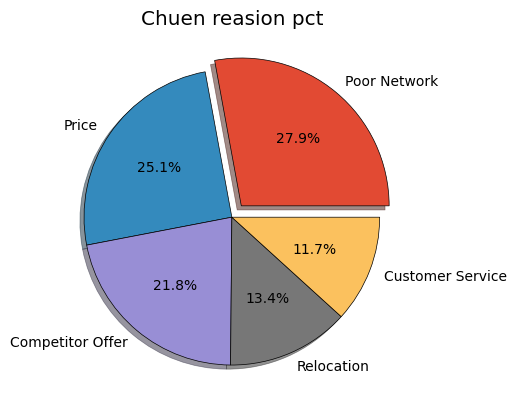

In [241]:
plt.style.use("ggplot")
df6 = df[df["churn_flag"] == 1]
df7 = pd.DataFrame(df6["churn_reason"].value_counts())
df7.reset_index(inplace = True)
values_ = np.array(df7["count"].tolist())
resion = df7["churn_reason"].tolist()
explode = np.arange(0 , len(values_))
explode[0 ::] = 0
explode = explode.astype(float)
max_value1 = np.argmax(values_)
explode[max_value1] = 0.1
plt.pie(values_ , labels=resion , wedgeprops= {"edgecolor" : "black" , "linestyle" : "-"} , shadow = True , autopct= "%1.1f%%" , explode = explode)
plt.title("Chuen reasion pct")